# Data augmentation in training labels
- We created augmentated audio recordings according to their corresponding labels in the training CSV split. As a basic principle, we always relate the audio or its Mels to their respective multi-hot labels.

In [1]:
import IPython.display as display
from IPython.display import display
from PIL import Image

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pathlib
import re
import seaborn as sns
import soundfile as sf
import librosa
import librosa.display
from audiomentations import AddGaussianNoise
from audiomentations import AddColorNoise
from audiomentations import LoudnessNormalization
from audiomentations import TanhDistortion
from audiomentations import AddGaussianNoise
from audiomentations import Limiter
from audiomentations import HighShelfFilter
from audiomentations import LowShelfFilter
from audiomentations import RepeatPart
from pedalboard import Pedalboard, Chorus
from pedalboard import Pedalboard, Reverb


In [2]:
# use Metropolis when it needed
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager as font_manager

font_path = r"C:/Users/Acer/AppData/Local/Microsoft/Windows/Fonts/"

metropolis_fonts = {
    "regular": "Metropolis-Regular.otf",
    "bold": "Metropolis-Bold.otf",
    "semibold": "Metropolis-SemiBold.otf",
    "light": "Metropolis-Light.otf",
    "medium": "Metropolis-Medium.otf",
    "black": "Metropolis-Black.otf",
    "extrabold": "Metropolis-ExtraBold.otf",
    "italic": "Metropolis-RegularItalic.otf"
}

# dictionary for FontProperties
metro = {}

for style, filename in metropolis_fonts.items():
    fullpath = os.path.join(font_path, filename)
    if os.path.exists(fullpath):
        font_manager.fontManager.addfont(fullpath)
        metro[style] = FontProperties(fname=fullpath)
    else:
        print(f"⚠️ Not found {filename}")

# 0. Basic setup

In [5]:
# ORIGINAL AUDIO PATH INPUT (FOLDER)
ORG_AUDIO_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\data\org_audio_pb"

In [6]:
# ORIGINAL LABELS PATH INPUT (CSV)
ORG_LABELS_TRAIN = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_pb.csv"
train_df = pd.read_csv(ORG_LABELS_TRAIN)
train_df.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI
3647,100_25_P2.wav,0,1,0,0,0,0,0,0,0
707,020_79_P2.wav,0,1,1,0,0,0,0,0,0
3493,096_42_P1.wav,0,0,1,0,0,0,0,0,0
3044,085_15_P2.wav,1,0,0,0,0,0,0,0,0
3217,089_47_P2.wav,0,0,1,0,0,0,0,0,0


In [7]:
# AUGMENTATED AUDIO PATH OUTPUT (FOLDER)
AUG_AUDIO_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb"
os.makedirs(AUG_AUDIO_DIR, exist_ok=True)

In [8]:
# AUGMENTATED LABELS PATH OUTPUT (CSV)
AUG_LABELS_TRAIN = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_aug_pb.csv"

In [9]:
CLASS_NAMES = ["TM","MH","VO","MU","EM","SO","BI","GE","SI"]

### Functions

In [10]:
# function to calculate Mels augmentation according our policy

def copies_for_row(row):
    combo = row["label_combo"]

    if combo in COMBINATION_AUG_FACTOR:
        extra_factor = COMBINATION_AUG_FACTOR[combo]
        return 1 + extra_factor

    return 1

In [11]:
# functions to apply up to 20 data augmentation techniques for audio

# =====================================================
# 1. POSITIVE PITCH SHIFT
# =====================================================

def pps(y, sr):
    return librosa.effects.pitch_shift(y=y, sr=sr, n_steps=+2)

# =====================================================
# 2. NEGATIVE PITCH SHIFT
# =====================================================

def nps(y, sr):
    return librosa.effects.pitch_shift(y=y, sr=sr, n_steps=-2)

# =====================================================
# 3. SLOW TIME STRETCH
# =====================================================

def sts(y, sr):
    if len(y) < 2048:
        print("STS SKIPPED, len =", len(y))
        return y
    return librosa.effects.time_stretch(y=y, rate=0.7)

# =====================================================
# 4. FAST TIME STRETCH
# =====================================================

def fts(y, sr):
    return librosa.effects.time_stretch(y=y, rate=1.2)

# =====================================================
# 5. TRIM DINÁMICO BASADO EN MÍNIMO RMS
# =====================================================

def trm(y, sr, drop_db=5):
    rms = librosa.feature.rms(
        y=y,
        frame_length=2048,
        hop_length=512
    )[0]

    rms_db = librosa.amplitude_to_db(rms, ref=np.max)

    max_rms_db = np.max(rms_db)
    min_rms_db = np.min(rms_db)
    rango_rms = max_rms_db - min_rms_db

    umbral_deseado = min_rms_db + drop_db

    if rango_rms < drop_db:
        umbral_aplicado = min_rms_db + (rango_rms - 1)
    else:
        umbral_aplicado = umbral_deseado

    top_db_auto = max_rms_db - umbral_aplicado
    if top_db_auto < 0.5:
        top_db_auto = 0.5

    y_trim, _ = librosa.effects.trim(
        y=y,
        top_db=top_db_auto,
        frame_length=2048,
        hop_length=512
    )

    return y_trim

# =====================================================
# 6. TIME DELAY
# =====================================================

def dly(y, sr, delay_ms=100, decay=0.8):
    delay_samples = int(sr * (delay_ms / 1000))
    y_out = np.zeros(len(y) + delay_samples, dtype=np.float32)
    y_out[:len(y)] += y
    y_out[delay_samples:] += y * decay
    return y_out

# =====================================================
# 7. GAUSSIAN NOISE
# =====================================================

gns_aug = AddGaussianNoise(
    min_amplitude=0.003, 
    max_amplitude=0.005, 
    p=1.0
)

def gns(y, sr):
    return gns_aug(samples=y, sample_rate=sr)

# =====================================================
# 8. PINK NOISE
# =====================================================

pns_aug = AddColorNoise(
    min_snr_db=15.0,
    max_snr_db=20.0,
    min_f_decay=-3.01,
    max_f_decay=-3.01,
    p=1.0
)

def pns(y, sr):
    return pns_aug(samples=y, sample_rate=sr)

# =====================================================
# 9. LOUDNESS NORMALIZATION
# =====================================================

lnm_aug = LoudnessNormalization(
    min_lufs=-90.0,
    max_lufs=-80.0,
    p=1.0
)

def lnm(y, sr):
    return lnm_aug(samples=y, sample_rate=sr)

# =====================================================
# 10 TANH DISTORTION (TND)
# =====================================================

tnd_aug = TanhDistortion(
    min_distortion=0.4,
    max_distortion=0.6,
    p=1.0
)

def tnd(y, sr):
    return tnd_aug(samples=y, sample_rate=sr)


# =====================================================
# 11. REVERB (RVB
# =====================================================

def rvb(y, sr):
    effect = Pedalboard([
        Reverb(
            room_size=0.25,
            wet_level=0.5,
            dry_level=0.5
        )
    ])
    return effect(y.astype(np.float32), sr).astype(np.float32)

# =====================================================
# 12. ADDITIVE WHITE NOISE (AWN)
# =====================================================

awn_aug = AddGaussianNoise(
    min_amplitude=0.002,
    max_amplitude=0.005,
    p=1.0
)

def awn(y, sr):
    return awn_aug(samples=y, sample_rate=sr)

# =====================================================
# 13. LIMITER (LMT)
# =====================================================

lmt_aug = Limiter(
    min_threshold_db=-10.0,
    max_threshold_db=-5.0,
    min_attack=0.001,
    max_attack=0.01,
    min_release=0.05,
    max_release=0.2,
    threshold_mode="relative_to_signal_peak",
    p=1.0
)

def lmt(y, sr):
    return lmt_aug(samples=y, sample_rate=sr)

# =====================================================
# 14. HIGH SHELF +dB (HSH+)
# =====================================================

hsh_plus_aug = HighShelfFilter(
    min_center_freq=2000.0,
    max_center_freq=8000.0,
    min_gain_db=10.0,
    max_gain_db=15.0,
    min_q=0.8,
    max_q=0.8,
    p=1.0
)

def hsh_plus(y, sr):
    return hsh_plus_aug(samples=y, sample_rate=sr)

# =====================================================
# 15. HIGH SHELF -dB (HSH-)
# =====================================================

hsh_minus_aug = HighShelfFilter(
    min_center_freq=2000.0,
    max_center_freq=8000.0,
    min_gain_db=-15.0,
    max_gain_db=-10.0,
    min_q=0.8,
    max_q=0.8,
    p=1.0
)

def hsh_minus(y, sr):
    return hsh_minus_aug(samples=y, sample_rate=sr)

# =====================================================
# 16. LOW SHELF +dB (PLS)
# =====================================================

lsh_plus_aug = LowShelfFilter(
    min_center_freq=50.0,
    max_center_freq=500.0,
    min_gain_db=10.0,
    max_gain_db=15.0,
    min_q=0.7,
    max_q=0.7,
    p=1.0
)

def lsh_plus(y, sr):
    return lsh_plus_aug(samples=y, sample_rate=sr)

# =====================================================
# 17. LOW SHELF -dB (NLS)
# =====================================================

lsh_minus_aug = LowShelfFilter(
    min_center_freq=50.0,
    max_center_freq=500.0,
    min_gain_db=-15.0,
    max_gain_db=-10.0,
    min_q=0.7,
    max_q=0.7,
    p=1.0
)

def lsh_minus(y, sr):
    return lsh_minus_aug(samples=y, sample_rate=sr)

# =====================================================
# 18. FLANGER DSP (FLG)
# =====================================================

def flg(y, sr):
    delay_ms = 1.0
    depth_ms = 0.1
    rate_hz  = 1.0
    feedback = 0.1
    mix      = 0.8

    y = y.astype(np.float32)
    n = len(y)
    delay_s = (delay_ms / 1000) * sr
    depth_s = (depth_ms / 1000) * sr

    t = np.arange(n) / sr
    lfo = np.sin(2 * np.pi * rate_hz * t)

    y_out = np.zeros(n, dtype=np.float32)
    fb = 0.0

    for i in range(n):
        d = delay_s + depth_s * lfo[i]
        idx = i - d

        if idx < 0:
            delayed = 0.0
        else:
            i0 = int(idx)
            frac = idx - i0
            if i0 + 1 < n:
                delayed = (1 - frac) * y[i0] + frac * y[i0+1]
            else:
                delayed = y[i0]

        delayed = delayed + fb * feedback
        y_out[i] = (1 - mix) * y[i] + mix * delayed
        fb = delayed

    maxv = np.max(np.abs(y_out))
    if maxv > 0.99:
        y_out = y_out / maxv

    return y_out.astype(np.float32)

# =====================================================
# 19. CHORUS (CHR) – pedalboard
# =====================================================

def chr(y, sr):
    effect = Pedalboard([
        Chorus(
            rate_hz=1.2,
            depth=0.8,
            centre_delay_ms=15.0,
            feedback=0.3,
            mix=0.6
        )
    ])
    return effect(y.astype(np.float32), sr).astype(np.float32)

# =====================================================
# 20. REPEATPART (RP) — audiomentations
# =====================================================

rp_aug = RepeatPart(
    min_repeats=1,
    max_repeats=2,
    min_part_duration=0.20,
    max_part_duration=0.60,
    mode="insert",
    crossfade_duration=0.0,
    p=1.0
)

def rp(y, sr):
    return rp_aug(samples=y, sample_rate=sr)


In [12]:
# function to apply all techniques defined in AUG_POLICY

def apply_aug_list(y, sr, combo):
    techniques = AUG_POLICY.get(combo, [])
    outputs = []

    for tech in techniques:
        func = AUG_FUNCS_x20[tech]
        y_aug = func(y, sr)
        outputs.append((tech, y_aug))

    return outputs

In [13]:
# function to generate label combinations from wav names

def build_label_combo(row):
    active = [lab for lab in CLASS_NAMES if row[lab] == 1]
    if len(active) == 0:
        return "NONE"
    return "+".join(active)

In [14]:
def label_combination(row):
    active = [lbl for lbl in CLASS_NAMES if row[lbl] == 1]
    return "+".join(active) if active else "NONE"

# 1. Exploratory statistical analysis

In [15]:
# BASIC STATISTICS
train_df["Label distributions"] = train_df[CLASS_NAMES].sum(axis=1)

print("Mean:", train_df["Label distributions"].mean())
print("Minimum:", train_df["Label distributions"].min())
print("Maximum:", train_df["Label distributions"].max())

print(train_df["Label distributions"].value_counts().sort_index())

Mean: 1.3122853368560106
Minimum: 1
Maximum: 3
Label distributions
1    2666
2    1056
3      63
Name: count, dtype: int64


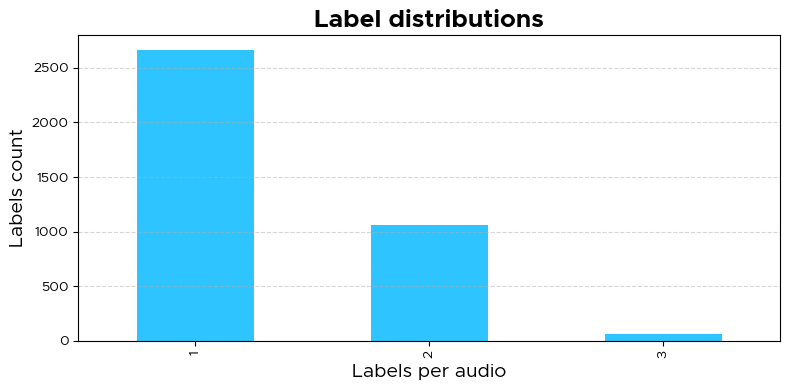

In [16]:
# LABEL DISTRIBUTION BY OVERLAPPING LABELS

plt.figure(figsize=(8, 4))

train_df["Label distributions"].value_counts().sort_index().plot(
    kind="bar",
    color="#2ec4ff"
)

plt.xlabel("Labels per audio", fontproperties=metro["regular"], fontsize=14)
plt.ylabel("Labels count", fontproperties=metro["regular"], fontsize=14)

plt.title(
    "Label distributions",
    fontproperties=metro["bold"],
    fontsize=18
)

plt.xticks(fontproperties=metro["regular"], fontsize=10)
plt.yticks(fontproperties=metro["regular"], fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [17]:
# drop label distributions colum

train_df = train_df.drop(columns=["Label distributions"])

# 2. Calculations for Mels augmentation

In [85]:
# AUG POLICY factors for stimate how many new labels we'll have:
# Do not inflate dominant classes.
# Increase rare and super‑rare classes as much as possible.
# Preserve the real context of rare‑class combinations with other classes,
# including strongly or moderately dominant ones.

COMBINATION_AUG_FACTOR = {


    # TM

    "TM": 2,
    "TM+VO": 10,
    "TM+MH": 4,

    # MH

    "MH": 2,
    "MH+VO": 2,
    
    # VO

    "VO": 2,

    # MU

    "MU": 10,
    "VO+MU": 10,
    "MH+VO+MU": 5,
    "MH+MU": 5,
    "TM+MU": 5,

    # EM

    "EM": 20,
    "TM+EM": 20,
    "VO+EM": 10,
    "TM+VO+EM": 10,
    "EM+BI": 10,
    "VO+EM+GE": 20,
    "MU+EM": 20,
    "MH+EM": 20,


    # SO

    "SO": 20,
    "MH+SO": 10,
    "MH+VO+SO": 20,


    # BI

    "BI": 20,
    "TM+BI": 15,
    "MH+BI": 6,
    "VO+BI": 10,
    "MH+VO+BI": 20,    
    "TM+EM+BI": 10, 
    "TM+BI+GE": 20,
    "TM+VO+BI": 20,
    "TM+MH+BI": 20,


    # GE

    "GE": 10,
    "TM+GE": 15,
    "VO+GE": 15,
    "EM+GE": 20,


    # SI

    "SI": 3,

}

In [86]:
# asegurar label_combo (fuente de verdad para TODAS las combinaciones)
train_df["label_combo"] = train_df.apply(label_combination, axis=1)

# combinaciones objetivo definidas por la política de data augmentation
policy_combos = list(COMBINATION_AUG_FACTOR.keys())
policy_combos_set = set(policy_combos)

In [87]:
# ==================================================
# LABEL COMBINATIONS (BEFORE) – ALL
# ==================================================

combo_counts_before_all = (
    train_df["label_combo"]
    .value_counts()
    .reset_index()
)

combo_counts_before_all.columns = ["Label combinations", "Before"]

In [88]:
# ==================================================
# LABEL COMBINATIONS (BEFORE) – POLICY ONLY
# ==================================================

combo_counts_before_policy = (
    combo_counts_before_all
    .set_index("Label combinations")
    .reindex(policy_combos, fill_value=0)
    .reset_index()
)

combo_counts_before_policy.columns = ["Label combinations", "Before"]

display(combo_counts_before_policy)

,Label combinations,Before
0,TM,913
1,TM+VO,135
2,TM+MH,44
3,MH,270
4,MH+VO,663
5,VO,709
6,MU,96
7,VO+MU,61
8,MH+VO+MU,12
9,MH+MU,22


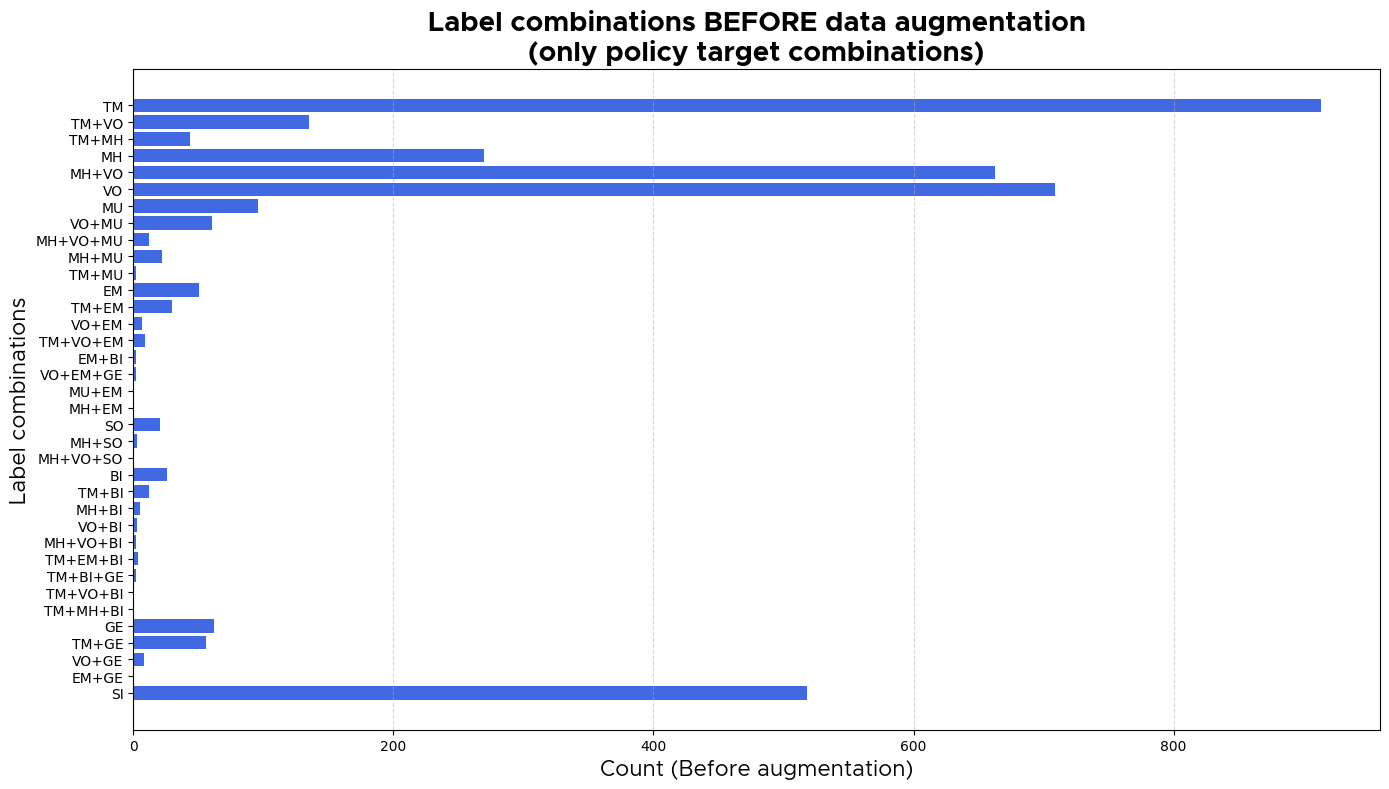

In [89]:
# ==================================================
# LABEL COMBINATIONS PLOT (BEFORE) – POLICY‑AWARE
# ==================================================

plot_df = combo_counts_before_policy.copy()

plt.figure(figsize=(14, 8))
plt.barh(
    plot_df["Label combinations"][::-1],
    plot_df["Before"][::-1],
    color="royalblue"
)

plt.xlabel("Count (Before augmentation)", fontproperties=metro["regular"], fontsize=16)
plt.ylabel("Label combinations", fontproperties=metro["regular"], fontsize=16)

plt.title(
    "Label combinations BEFORE data augmentation\n(only policy target combinations)",
    fontproperties=metro["bold"], fontsize=20
)

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [90]:
# ==================================================
# LABEL COMBINATIONS (AFTER) – ALL
# ==================================================

combo_counts_after_all = {}

for _, row in train_df.iterrows():
    combo = row["label_combo"]
    copies = copies_for_row(row)
    combo_counts_after_all[combo] = combo_counts_after_all.get(combo, 0) + copies

combo_counts_after_all = (
    pd.Series(combo_counts_after_all)
    .reset_index()
)

combo_counts_after_all.columns = ["Label combinations", "After"]

In [91]:
# ==================================================
# LABEL COMBINATIONS (AFTER) – POLICY ONLY
# ==================================================

combo_counts_after_policy = (
    combo_counts_after_all
    .set_index("Label combinations")
    .reindex(policy_combos, fill_value=0)
    .reset_index()
)

combo_counts_after_policy.columns = ["Label combinations", "After"]

display(combo_counts_after_policy)

,Label combinations,After
0,TM,2739
1,TM+VO,1485
2,TM+MH,220
3,MH,810
4,MH+VO,1989
5,VO,2127
6,MU,1056
7,VO+MU,671
8,MH+VO+MU,72
9,MH+MU,132


In [92]:
# ==================================================
# COMPARE BEFORE vs AFTER – POLICY ONLY
# ==================================================

combo_compare = (
    combo_counts_before_policy
    .set_index("Label combinations")
    .join(
        combo_counts_after_policy.set_index("Label combinations"),
        how="left"
    )
    .fillna(0)
    .reset_index()
)

combo_compare["Before"] = combo_compare["Before"].astype(int)
combo_compare["After"] = combo_compare["After"].astype(int)
combo_compare["Increase"] = combo_compare["After"] - combo_compare["Before"]

combo_compare["Effective_factor"] = (
    combo_compare["After"] /
    combo_compare["Before"].replace(0, np.nan)
)

combo_compare

,Label combinations,Before,After,Increase,Effective_factor
0,TM,913,2739,1826,3.0
1,TM+VO,135,1485,1350,11.0
2,TM+MH,44,220,176,5.0
3,MH,270,810,540,3.0
4,MH+VO,663,1989,1326,3.0
5,VO,709,2127,1418,3.0
6,MU,96,1056,960,11.0
7,VO+MU,61,671,610,11.0
8,MH+VO+MU,12,72,60,6.0
9,MH+MU,22,132,110,6.0


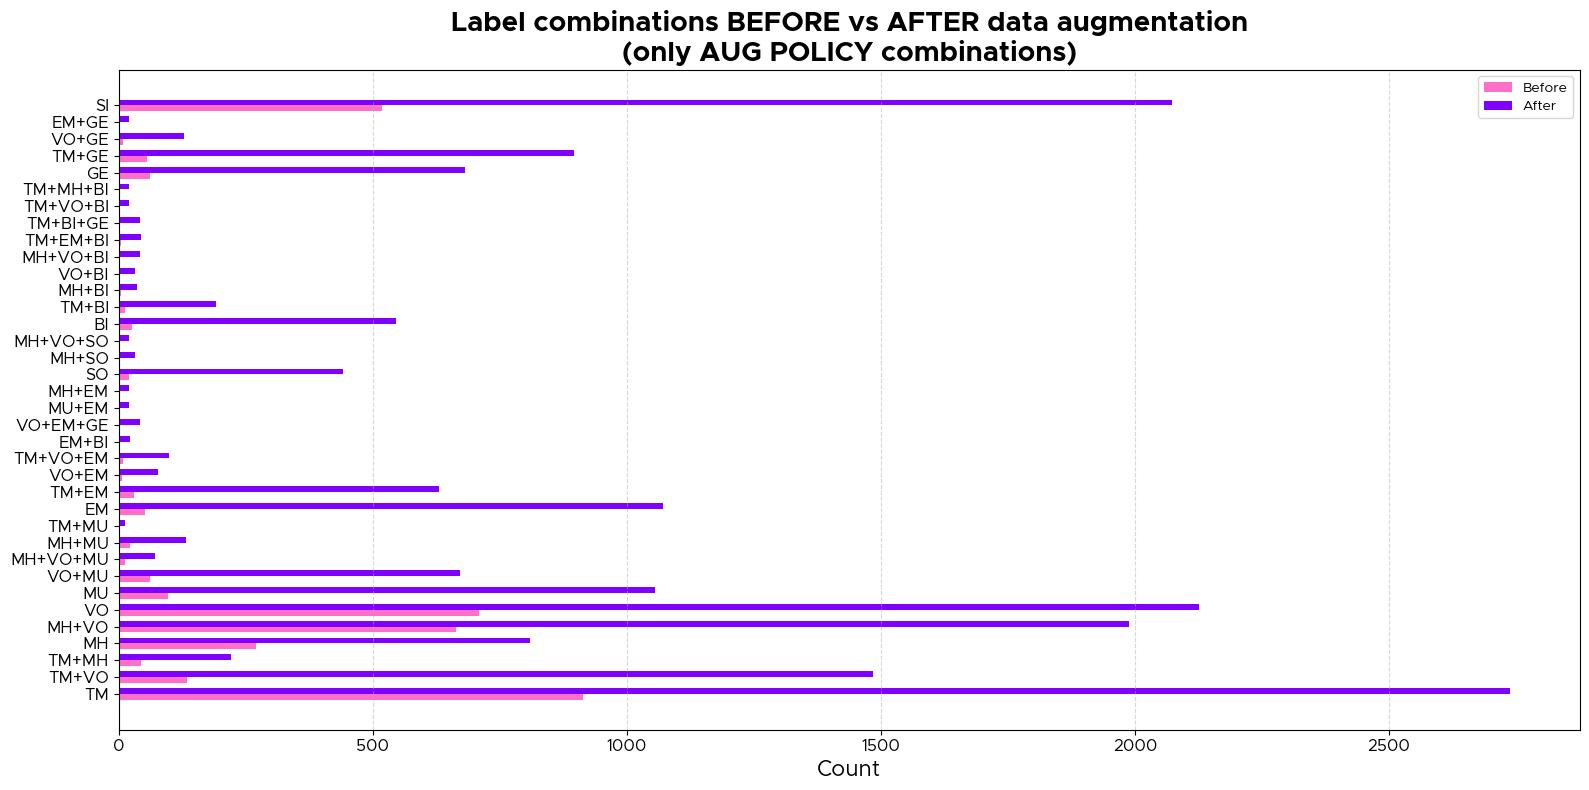

In [93]:
# ==================================================
# PLOT: BEFORE vs AFTER (POLICY‑AWARE)
# ==================================================

palette_80s = {
    "before": "#ff6ec7",   # vaporwave pink
    "after":  "#7f00ff",   # neon violet
}

# Usar EXACTAMENTE el orden definido en la policy
policy_combos = list(COMBINATION_AUG_FACTOR.keys())

plot_df = (
    combo_compare
    .set_index("Label combinations")
    .reindex(policy_combos, fill_value=0)
    .reset_index()
)

plt.figure(figsize=(16, 8))

y = np.arange(len(plot_df))
height = 0.35

# BEFORE
plt.barh(
    y - height / 2,
    plot_df["Before"],
    height,
    label="Before",
    color=palette_80s["before"]
)

# AFTER
plt.barh(
    y + height / 2,
    plot_df["After"],
    height,
    label="After",
    color=palette_80s["after"]
)

plt.yticks(
    y,
    plot_df["Label combinations"],
    fontproperties=metro["regular"],
    fontsize=12
)

plt.xlabel(
    "Count",
    fontproperties=metro["regular"],
    fontsize=16
)

plt.title(
    "Label combinations BEFORE vs AFTER data augmentation\n(only AUG POLICY combinations)",
    fontproperties=metro["bold"],
    fontsize=20
)

plt.xticks(fontproperties=metro["regular"], fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.legend(
    prop=metro["regular"],
    title_fontproperties=metro["bold"]
)

plt.tight_layout()
plt.show()

In [94]:
# compare global classes befor and after data augmentation
 
class_counts_before = train_df[CLASS_NAMES].sum()

# final class label counts after augmentation
class_counts_after = {cls: 0 for cls in CLASS_NAMES}

for _, row in train_df.iterrows():
    copies = copies_for_row(row)

    for cls in CLASS_NAMES:
        if row[cls] == 1:
            class_counts_after[cls] += copies

class_counts_after = pd.Series(class_counts_after)

# comparison
class_compare = pd.DataFrame({
    "Before": class_counts_before,
    "After": class_counts_after,
})

# absolute difference
class_compare["Increse"] = (
    class_compare["After"] - class_compare["Before"]
)

class_compare

,Before,After,Increse
TM,1238,6430,5192
MH,1053,3425,2372
VO,1642,6836,5194
MU,194,1964,1770
EM,108,2048,1940
SO,25,495,470
BI,58,998,940
GE,131,1811,1680
SI,518,2072,1554


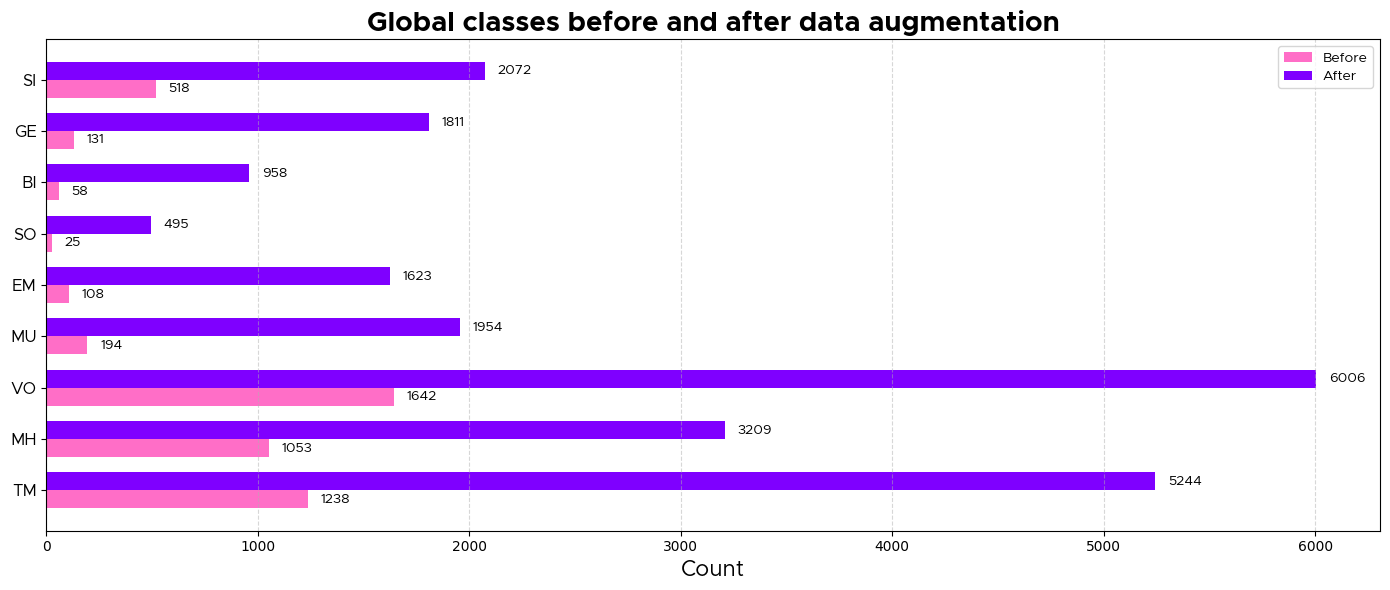

In [55]:
# plot comaprison

palette_80s = {
    "before": "#ff6ec7",
    "after":  "#7f00ff",
}

plt.figure(figsize=(14, 6))

y = np.arange(len(CLASS_NAMES))
height = 0.35

plt.barh(
    y - height/2,
    class_compare["Before"],
    height,
    label="Before",
    color=palette_80s["before"]
)

plt.barh(
    y + height/2,
    class_compare["After"],
    height,
    label="After",
    color=palette_80s["after"]
)

# Y‑axis labels (classes)
plt.yticks(y, CLASS_NAMES, fontproperties=metro["regular"], fontsize=12)
plt.xlabel("Count", fontproperties=metro["regular"], fontsize=16)
plt.title(
    "Global classes before and after data augmentation",
    fontproperties=metro["bold"],
    fontsize=20
)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.legend(prop=metro["regular"], title_fontproperties=metro["bold"])

for i, cls in enumerate(CLASS_NAMES):

    val_before = class_compare.loc[cls, "Before"]
    val_after  = class_compare.loc[cls, "After"]

    # Text for “Before”
    plt.text(
        val_before + max(class_compare["After"]) * 0.01,
        y[i] - height/2,
        str(int(val_before)),
        va="center",
        ha="left",
        fontsize=10,
        fontproperties=metro["regular"]
    )

    # Text for “After”
    plt.text(
        val_after + max(class_compare["After"]) * 0.01,
        y[i] + height/2,
        str(int(val_after)),
        va="center",
        ha="left",
        fontsize=10,
        fontproperties=metro["regular"]
    )

plt.tight_layout()
plt.show()

In [95]:
# ==================================================
# SEE EACH CLASS AND ITS COMBINATIONS (AFTER ONLY)
# INCLUDING POLICY + NON‑POLICY COMBOS
# AUGMENTED == factor > 0
# ==================================================

after_full_df = combo_counts_after_all.copy()

# ✅ Marcar como aumentada SOLO si el factor en la policy es > 0
after_full_df["Augmented_by_policy"] = (
    after_full_df["Label combinations"]
    .apply(lambda c: COMBINATION_AUG_FACTOR.get(c, 0) > 0)
)

for cls in CLASS_NAMES:

    sub = after_full_df[
        after_full_df["Label combinations"].apply(
            lambda comb: cls in comb.split("+")
        )
    ].copy()

    if sub.empty:
        print(f"\nCLASS: {cls}  |  NO combinations found after augmentation\n")
        continue

    print("\n" + "=" * 100)
    print(f"CLASS: {cls}  |  AFTER data augmentation (ALL combinations)")
    print("=" * 100)

    # Fila TOTAL por clase
    total_row = pd.DataFrame({
        "Label combinations": [f"TOTAL {cls}"],
        "After": [sub["After"].sum()],
        "Augmented_by_policy": [""]
    })

    sub_final = pd.concat([sub, total_row], ignore_index=True)

    display(
        sub_final[
            ["Label combinations", "After", "Augmented_by_policy"]
        ].sort_values("After", ascending=False)
    )


CLASS: TM  |  AFTER data augmentation (ALL combinations)


,Label combinations,After,Augmented_by_policy
13,TOTAL TM,6430,
0,TM,2739,True
2,TM+VO,1485,True
4,TM+GE,896,True
7,TM+EM,630,True
1,TM+MH,220,True
5,TM+BI,192,True
6,TM+VO+EM,99,True
8,TM+EM+BI,44,True
10,TM+BI+GE,42,True



CLASS: MH  |  AFTER data augmentation (ALL combinations)


,Label combinations,After,Augmented_by_policy
12,TOTAL MH,3425,
4,MH+VO,1989,True
0,MH,810,True
1,TM+MH,220,True
6,MH+MU,132,True
7,MH+VO+MU,72,True
3,MH+VO+BI,42,True
2,MH+BI,35,True
10,MH+SO,33,True
5,TM+MH+VO,29,False



CLASS: VO  |  AFTER data augmentation (ALL combinations)


...

,Label combinations,After,Augmented_by_policy
10,TOTAL BI,998,
1,BI,546,True
4,TM+BI,192,True
5,TM+EM+BI,44,True
3,MH+VO+BI,42,True
8,TM+BI+GE,42,True
2,MH+BI,35,True
0,VO+BI,33,True
6,EM+BI,22,True
7,TM+VO+BI,21,True



CLASS: GE  |  AFTER data augmentation (ALL combinations)


,Label combinations,After,Augmented_by_policy
6,TOTAL GE,1811,
3,TM+GE,896,True
1,GE,682,True
0,VO+GE,128,True
2,VO+EM+GE,42,True
5,TM+BI+GE,42,True
4,EM+GE,21,True



CLASS: SI  |  AFTER data augmentation (ALL combinations)


,Label combinations,After,Augmented_by_policy
0,SI,2072,True
1,TOTAL SI,2072,


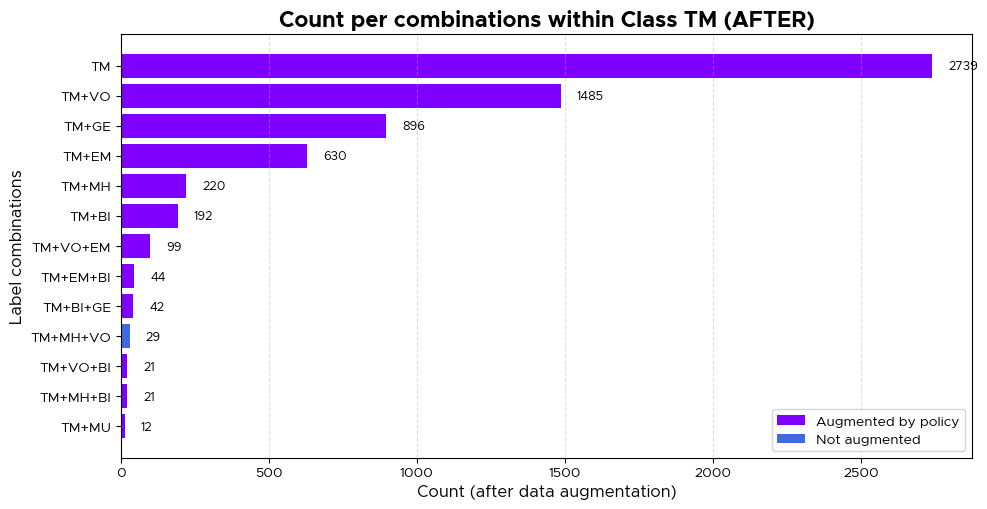

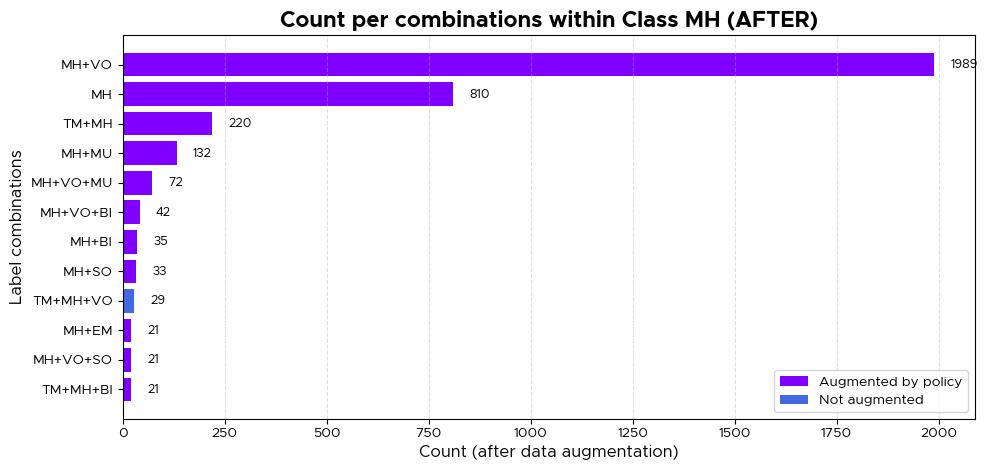

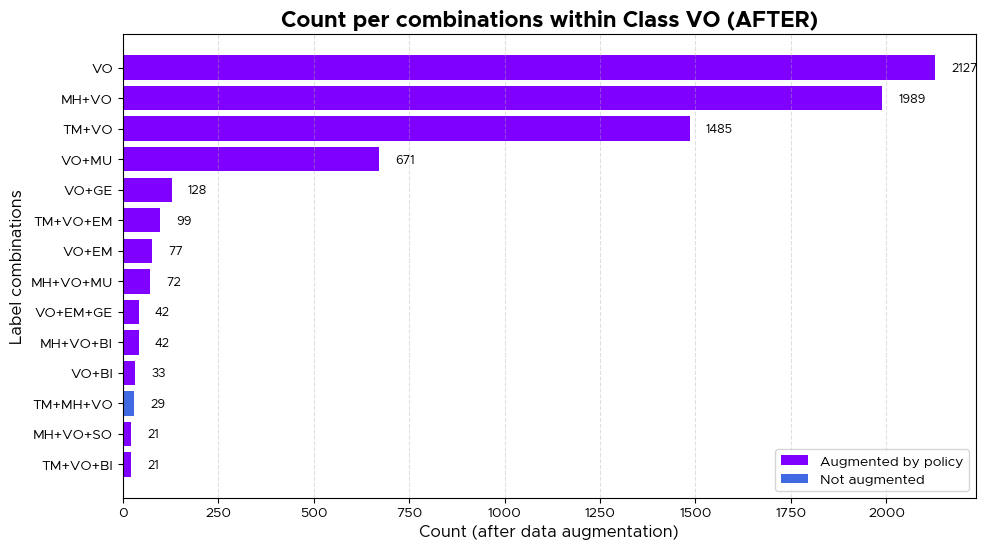

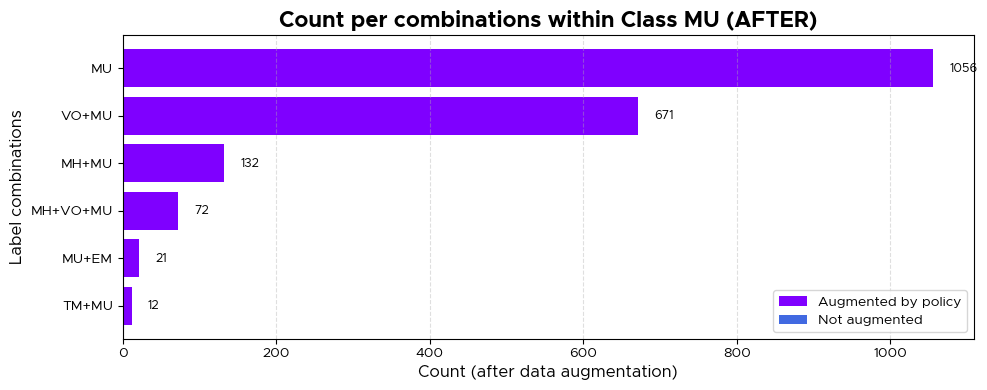

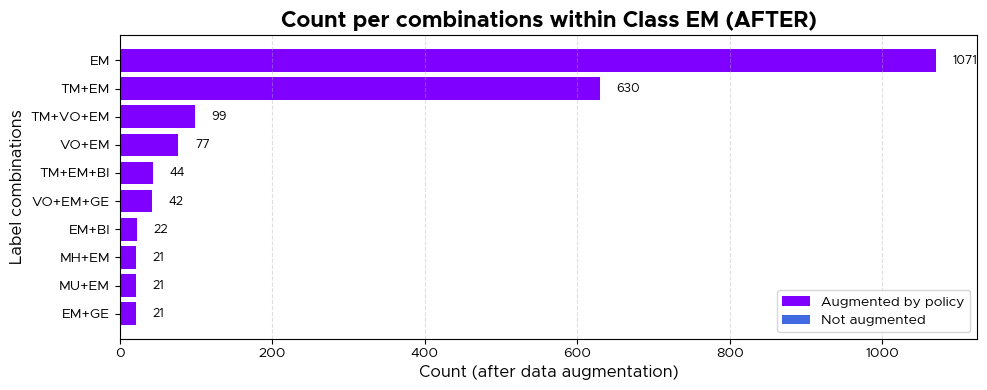

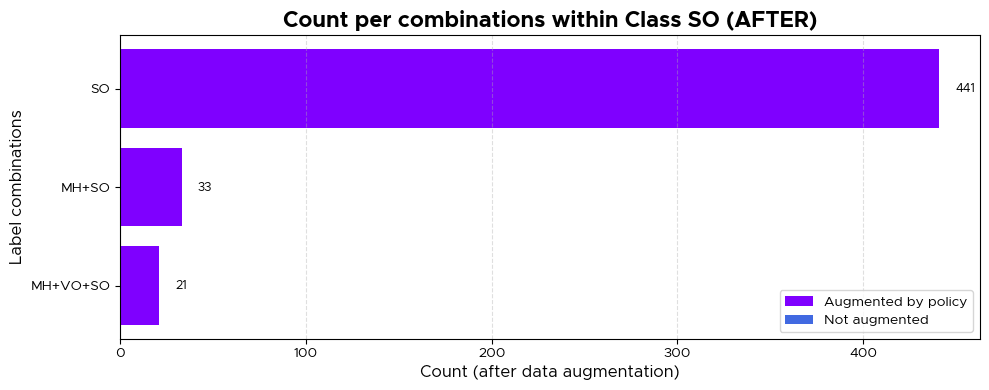

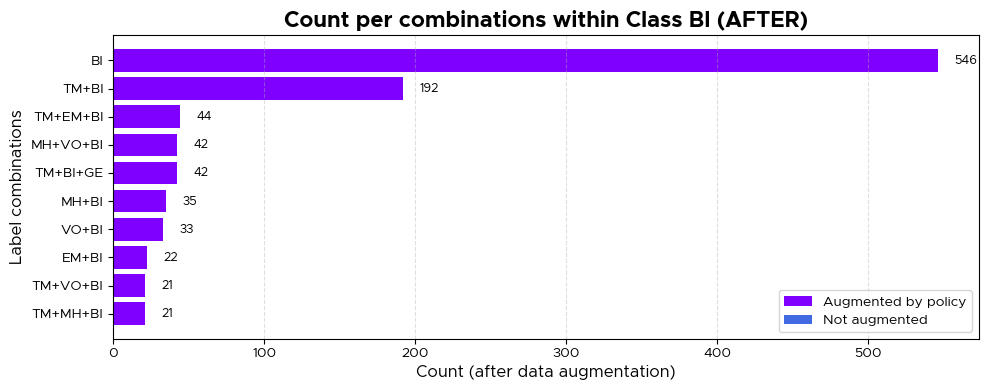

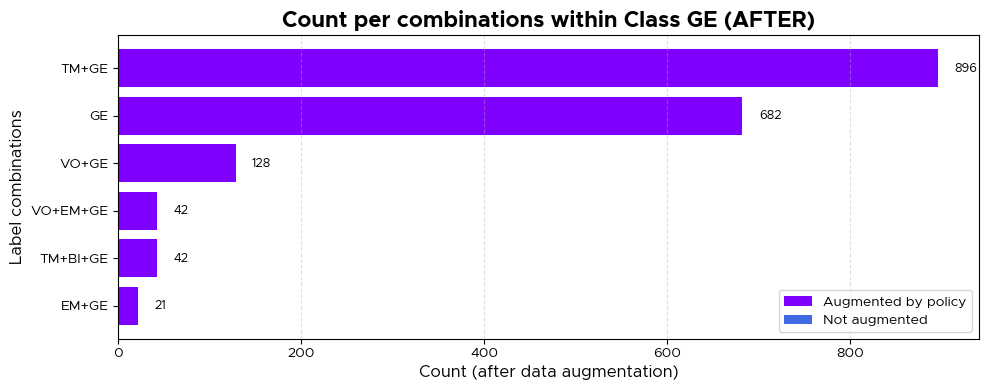

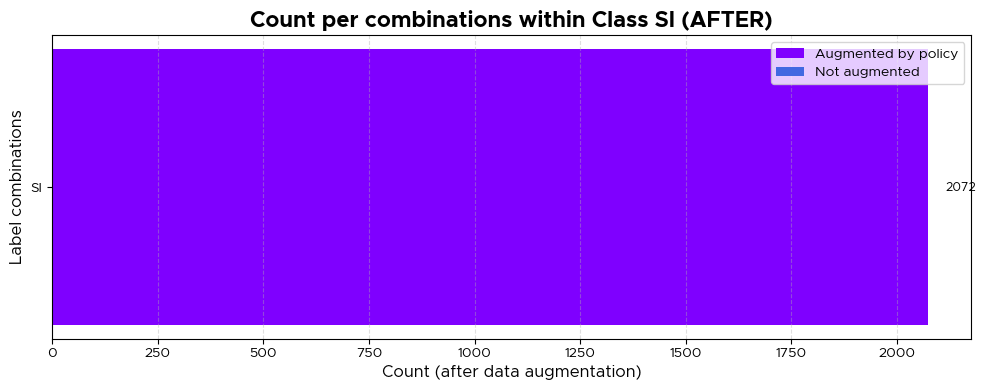

In [97]:
# ==================================================
# PLOT: Combinations by class (AFTER ONLY)
# Including augmented + non‑augmented combinations
# ==================================================

for cls in CLASS_NAMES:

    # Filtrar TODAS las combinaciones AFTER donde la clase aparece como token exacto
    sub = after_full_df[
        after_full_df["Label combinations"].apply(
            lambda comb: cls in comb.split("+")
        )
    ].copy()

    if sub.empty:
        print(f"\nCLASS {cls}: without combinations after augmentation.\n")
        continue

    # Ordenar por peso final (AFTER)
    sub = sub.sort_values("After", ascending=False)

    plt.figure(figsize=(10, max(4, 0.4 * len(sub))))

    # Color según si la combinación fue aumentada o no
    colors = sub["Augmented_by_policy"].map(
        {True: "#7f00ff", False: "royalblue"}
    )

    plt.barh(
        sub["Label combinations"],
        sub["After"],
        color=colors
    )

    plt.gca().invert_yaxis()

    plt.title(
        f"Count per combinations within Class {cls} (AFTER)",
        fontproperties=metro["bold"],
        fontsize=16
    )

    plt.xlabel(
        "Count (after data augmentation)",
        fontproperties=metro["regular"],
        fontsize=12
    )

    plt.ylabel(
        "Label combinations",
        fontproperties=metro["regular"],
        fontsize=12
    )

    plt.yticks(
        fontproperties=metro["regular"],
        fontsize=10
    )
    plt.xticks(
        fontproperties=metro["regular"],
        fontsize=10
    )

    # Etiquetas numéricas
    max_val = sub["After"].max()
    for _, row in sub.iterrows():
        plt.text(
            row["After"] + max_val * 0.02,
            row["Label combinations"],
            int(row["After"]),
            va="center",
            fontproperties=metro["regular"],
            fontsize=9
        )

    # Leyenda manual (augmented vs non‑augmented)
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor="#7f00ff", label="Augmented by policy"),
        Patch(facecolor="royalblue", label="Not augmented"),
    ]

    plt.legend(
        handles=legend_elements,
        prop=metro["regular"],
        title_fontproperties=metro["bold"]
    )

    plt.grid(axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


# 3. Apply augmentations

Following the previous analysis in the calculation of the labels increase to be achieved, we decided on strong increases in moderately rare or super rare classes and to contain the increase of the strongly dominant classes as much as possible. Likewise, we always prioritized increasing when the sound classes were isolated, and we only increased combinations of overlapping classes when they contributed to the rarer classes, as an inevitable part of the context of sound superposition in urban areas.

In [98]:
# AUG dictionary

AUG_FUNCS_x20 = {
    "PPS": pps,          # Pitch +2
    "NPS": nps,          # Pitch -2
    "STS": sts,          # Slow stretch
    "FTS": fts,          # Fast stretch
    "TRM": trm,          # Trim dinámico
    "DLY": dly,          # Delay DSP

    "GNS": gns,          # Gaussian noise
    "PNS": pns,          # Pink noise
    "AWN": awn,          # White noise

    "LNM": lnm,          # Loudness normalization
    "TND": tnd,          # Tanh distortion
    "RVB": rvb,          # Reverb DSP

    "LMT": lmt,          # Limiter

    "HSH": hsh_plus,     # High-shelf +dB
    "NHS": hsh_minus,    # High-shelf -dB

    "PLS": lsh_plus,     # Low-shelf +dB
    "NLS": lsh_minus,    # Low-shelf -dB

    "FLG": flg,          # Flanger DSP
    "CHR": chr,          # Chorus
    "RP": rp,            # RepeatPart
}

In [99]:
# ALL AVAILABLE TECHNIQUES

ALL_TECHS = [
    "PPS","NPS",          # pitch
    "STS","FTS",          # time stretch
    "TRM","DLY",          # trim, delay DSP
    "GNS","PNS","AWN",    # noise
    "LNM","TND","RVB",    # loudness, distortion, reverb
    "LMT",                # limiter
    "HSH","NHS",          # high-shelf +/- dB
    "PLS","NLS",          # low-shelf +/- dB
    "FLG","CHR","RP"      # flanger, chorus, repeat-part
]

In [102]:
AUG_POLICY = {

    # ========= TM =========
    "TM": ["PNS", "STS"],

    "TM+VO": [
        "STS","FTS","TRM","DLY","RVB",
        "LNM","PNS","CHR","FLG","RP"
    ],

    "TM+MH": [
        "STS","FTS","TRM","RP"
    ],


    # ========= MH =========
    "MH": ["PNS","STS"],

    "MH+VO": ["NPS","FTS"],


    # ========= VO =========
    "VO": ["TRM","DLY"],


    # ========= MU =========
    "MU": [
        "PPS","NPS","STS","FTS",
        "TRM","RP",
        "LNM","RVB","NLS","PLS"
    ],

    "VO+MU": [
        "STS","FTS","TRM","RP","DLY",
        "RVB","LNM","PNS","CHR","FLG"
    ],

    "MH+VO+MU": [
        "STS","FTS","TRM","RP","DLY"
    ],

    "MH+MU": [
        "STS","FTS","TRM","RP","DLY"
    ],

    "TM+MU": [
        "STS","FTS","TRM","RP","DLY"
    ],


    # ========= EM =========
    "EM": ALL_TECHS[:20],

    "TM+EM": ALL_TECHS[:20],

    "VO+EM": [
        "STS","FTS","TRM","DLY","RP",
        "RVB","LNM","PNS","CHR","FLG"
    ],

    "TM+VO+EM": [
        "STS","FTS","TRM","RP","DLY",
        "RVB","LNM","PNS","CHR","FLG"
    ],

    "EM+BI": [
        "STS","FTS","RVB","TND","CHR",
        "PLS","HSH","NLS","RP","PNS"
    ],

    "VO+EM+GE": ALL_TECHS[:20],

    "MU+EM": ALL_TECHS[:20],

    "MH+EM": ALL_TECHS[:20],


    # ========= SO =========
    "SO": ALL_TECHS[:20],

    "MH+SO": [
        "STS","FTS","TRM","DLY",
        "RVB","TND",
        "PNS","RP","CHR","FLG"
    ],

    "MH+VO+SO": ALL_TECHS[:20],


    # ========= BI =========
    "BI": ALL_TECHS[:20],

    "TM+BI": [
        "STS","FTS",
        "TRM","DLY",
        "RVB","NPS","LNM",
        "PNS","RP","CHR",
        "FLG","PLS","HSH",
        "NLS","PPS"
    ],

    "MH+BI": [
        "STS","FTS","TRM","RVB","TND","RP"
    ],

    "VO+BI": [
        "STS","FTS","TRM","DLY",
        "RVB","TND",
        "PNS","RP","CHR","FLG"
    ],

    "MH+VO+BI": ALL_TECHS[:20],

    "TM+EM+BI": [
        "STS","FTS",
        "TRM","DLY",
        "RVB","TND",
        "PNS","RP","CHR","FLG"
    ],

    "TM+BI+GE": ALL_TECHS[:20],

    "TM+VO+BI": ALL_TECHS[:20],

    "TM+MH+BI": ALL_TECHS[:20],


    # ========= GE =========
    "GE": [
        "STS","FTS",
        "TRM","DLY",
        "RVB","PPS","NPS",
        "PNS","CHR","FLG"
    ],

    "TM+GE": [
        "STS","FTS",
        "TRM","DLY",
        "RVB","PPS","NPS",
        "RP","CHR","FLG",
        "HSH","NHS","PLS","NLS","LMT"
    ],

    "VO+GE": [
        "STS","FTS",
        "TRM","DLY",
        "RVB","PPS","NPS",
        "RP","CHR","FLG",
        "HSH","NHS","PLS","NLS","LMT"
    ],

    "EM+GE": ALL_TECHS[:20],


    # ========= SI =========
    "SI": ["STS","PPS","NPS"],
}

In [103]:
# get label combinations

train_df["label_combo"] = train_df.apply(build_label_combo, axis=1)
train_df.sample(5)

,filename,TM,MH,VO,MU,EM,SO,BI,GE,SI,label_combo
667,019_79_P1.wav,0,0,0,0,0,0,1,0,0,BI
272,007_81_P1.wav,0,0,0,0,0,0,0,0,1,SI
675,020_08_P1.wav,0,1,1,0,0,0,0,0,0,MH+VO
2872,080_78_P2.wav,1,0,0,0,0,0,0,1,0,TM+GE
576,017_53_P2.wav,0,0,0,0,0,0,0,0,1,SI


In [104]:
# get augmented audio

AUG_ROWS = []

written_files = set()
overwritten_files = set()
total_written = 0

print("🚀 Starting audio augmentation...\n")

for idx, row in train_df.iterrows():

    combo = row["label_combo"]
    fname = row["filename"]

    fpath = os.path.join(ORG_AUDIO_DIR, fname)
    y, sr = librosa.load(fpath, sr=None)

    aug_versions = apply_aug_list(y, sr, combo)

    for tech, y_aug in aug_versions:
        new_name = f"{fname.replace('.wav','')}_AUG_{tech}.wav"
        out_path = os.path.join(AUG_AUDIO_DIR, new_name)

        # check overwrite
        if os.path.exists(out_path):
            overwritten_files.add(new_name)
            status = "⚠️ OVERWRITE"
        else:
            status = "✅ NEW"

        # save WAV
        sf.write(out_path, y_aug, sr)
        written_files.add(new_name)
        total_written += 1

        # log
        print(f"{status} → Saved in: {out_path}")

        # store row
        AUG_ROWS.append({
            "filename": new_name,
            "label_combo": combo,
            **{lab: row[lab] for lab in CLASS_NAMES},
            "aug": tech
        })

print("\n✅ Audio augmentation finished.\n")

🚀 Starting audio augmentation...

✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_05_P2_AUG_PNS.wav
✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_05_P2_AUG_STS.wav
✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_06_P1_AUG_PNS.wav
✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_06_P1_AUG_STS.wav
✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_09_P1_AUG_PNS.wav
✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_09_P1_AUG_STS.wav
✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_10_P2_AUG_PNS.wav
✅ NEW → Saved in: C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\aug_audio_pb\001_10_P2_AUG_STS.wav
✅ NEW 

In [106]:
# checks

print("\n📊 AUGMENTATION SUMMARY")
print(f"Total WAV write operations: {total_written}")
print(f"Unique WAV files present:  {len(written_files)}")
print(f"WAV files overwritten:     {len(overwritten_files)}")

if overwritten_files:
    print("\n⚠️ Overwritten files:")
    for f in sorted(overwritten_files):
        print(" -", f)
else:
    print("\n✅ No overwrites detected")


📊 AUGMENTATION SUMMARY
Total WAV write operations: 14810
Unique WAV files present:  14810
WAV files overwritten:     0

✅ No overwrites detected


In [107]:
# export CSV with augmentated labels

aug_df = pd.DataFrame(AUG_ROWS)
aug_df.to_csv(AUG_LABELS_TRAIN, index=False)

print("✅ CSV created at:")
print(AUG_LABELS_TRAIN)

# CSV stats
csv_filenames = set(aug_df["filename"])
num_csv_rows = len(aug_df)

# Folder stats
wav_files = {
    f for f in os.listdir(AUG_AUDIO_DIR)
    if f.lower().endswith(".wav")
}
num_wav_files = len(wav_files)

✅ CSV created at:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\1_mels_generation-py-R\results\train_df_aug_pb.csv


In [108]:
# checks

print("\n📊 CONSISTENCY CHECK")
print(f"CSV rows:          {num_csv_rows}")
print(f"WAV files in dir:  {num_wav_files}")


csv_not_in_folder = csv_filenames - wav_files
folder_not_in_csv = wav_files - csv_filenames

if not csv_not_in_folder and not folder_not_in_csv:
    print("\n✅ PERFECT MATCH")
    print("CSV records and audio files are perfectly synchronized (1:1)")
else:
    if csv_not_in_folder:
        print("\n❌ CSV entries without WAV file:")
        for f in sorted(csv_not_in_folder):
            print(" -", f)

    if folder_not_in_csv:
        print("\n❌ WAV files without CSV entry:")
        for f in sorted(folder_not_in_csv):
            print(" -", f)

print("\n✅ Verification completed.\n")

aug_df.sample(5)


📊 CONSISTENCY CHECK
CSV rows:          14810
WAV files in dir:  14810

✅ PERFECT MATCH
CSV records and audio files are perfectly synchronized (1:1)

✅ Verification completed.



,filename,label_combo,TM,MH,VO,MU,EM,SO,BI,GE,SI,aug
10070,075_59_P2_AUG_STS.wav,SI,0,0,0,0,0,0,0,0,1,STS
5851,044_77_P1_AUG_STS.wav,TM+MH,1,1,0,0,0,0,0,0,0,STS
1991,015_12_P2_AUG_PNS.wav,TM,1,0,0,0,0,0,0,0,0,PNS
6836,055_67_P2_AUG_FLG.wav,VO+MU,0,0,1,1,0,0,0,0,0,FLG
11636,081_43_P1_AUG_NLS.wav,MU,0,0,0,1,0,0,0,0,0,NLS
